In [1]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
#Importar os dados e verificar dimens~oes
df_train = pd.read_pickle('Xtrain.pkl')
#print(df_train.shape)
#Concatenar todas as poses e sequ^encias numa matriz de dados.
#Esta matriz vai ser usada na maior parte do projeto
X = np.concatenate(df_train['Skeleton_Sequence'].to_numpy())
#print(X.shape) # N X 66
#Normaliza¸c~ao dos dados - centrar + escalamento (recomendando e cr´ıtico para o PCA)
scaler = StandardScaler()
X_norm = scaler.fit_transform(X)
#Aceder a uma sequ^encia espec´ıfica do dataframe, por exemplo a primeira
#seq = df_train.iloc[0]['Skeleton_Sequence']
#print(seq.shape) # T X 66





# Não MODIFICAR A SEED
np.random.seed(555)

def kminit(X, K, flag):
    #Inicialização - pode ser aleatória ou recorrendo ao k-means++
    # A inicialização do primeiro centróide é fixa
    N = X.shape[0]
    C = []
    primeiro = np.random.randint(N)
    C.append(X[primeiro])


    #complete o código para inicializar os K-1 centróides de acordo com a flag

    if flag == 'random':
        #o codigo já pos um centroide em C, faltam 
        retirarescolhido = np.delete(np.arange(N), primeiro)
        #sorteamos K-1 indices diferentes
        indices = np.random.choice(retirarescolhido, size=K-1, replace=False)
        #juntar a lista de centroides
        for idx in indices:
            C.append(X[idx])

    elif flag == 'km++':
        for _ in range(K-1):
            centroides_escolhidos = np.array(C)
            #distancia ao quadrado de cada ponto a cada centroide (N,m)
            distancia = np.sum((X[:, np.newaxis, :] - centroides_escolhidos[np.newaxis, :, :]) ** 2, axis=2)
            #distancia ao centroide + proximo
            minima_distancia = np.min(distancia, axis=1)
            probabilidade = minima_distancia/np.sum(minima_distancia)

            #sortear ponto
            idx = np.random.choice(N, p=probabilidade)
            C.append(X[idx])

    else:
        print("A flag deve ser random ou km++")

    return np.array(C)




def kmeans_custo(X, C, s):
#Calcula a funcão de custo do k-means
#centroide de cada ponto

    centros_atribuidos = C[s]

    #distancia euclidiana ao quadrado
    distancia_J = np.sum((X - centros_atribuidos)** 2, axis=1)
    #custo total
    J = np.sum(distancia_J)


#devolve a distancia ao quad de cada ponto ao seu centroide e a soma de tudo = J
    return distancia_J, J



#R1 iv - associar pontos aos centróides

def kmeans_atribuir(X,C):
    #Associa cada ponto ao centróide mais próximo.
    #distancia ao quadrado de cada ponto a cada centroide
    dist = np.sum((X[:, np.newaxis, :] - C[np.newaxis, :, :]) ** 2, axis=2)
    #indice do centroide + perto
    return np.argmin(dist, axis=1)


def kmeans(X, K, flag, max_iter=300, tol=1e-6):
#Aplica o algoritm k-means a matriz de dados X.
    N, d = X.shape

    #inicializar
    centroides = kminit(X, K, flag)
    J_inicial = None

    for _ in range(max_iter):
        #atribuição
        atribuir = kmeans_atribuir(X, centroides)

        #atualizar
        centroide_novo = np.zeros((K, d))
        for k in range(K):
            pontos_k = X[atribuir == k]
            if len(pontos_k) > 0:
                centroide_novo[k] = pontos_k.mean(axis=0)
            else:
                #cluster vazio - começa num ponto qualquer
                centroide_novo[k] = X[np.random.randint(N)]
        centroides = centroide_novo

        #paragem = J nao muda
        _, J_atual = kmeans_custo(X, centroides, atribuir)
        if J_inicial is not None and abs(J_inicial - J_atual) < tol: 
            break
        J_inicial = J_atual

    #atribuição final
    atribuir = kmeans_atribuir(X, centroides)
    return centroides, atribuir







In [2]:
centroides, atribuir = kmeans(X_norm, 5, 'km++')
print(centroides.shape, atribuir.shape, np.bincount(atribuir))
_, J = kmeans_custo(X_norm, centroides, atribuir)
print("J =", J)

(5, 66) (8374,) [ 719 5223  838 1202  392]
J = 205756.40423512345


K =  1  ->  J = 552684.00
K =  2  ->  J = 451679.55
K =  3  ->  J = 346002.62
K =  4  ->  J = 312576.68
K =  5  ->  J = 219189.00
K =  6  ->  J = 178013.86
K =  7  ->  J = 151110.33
K =  8  ->  J = 140598.14
K =  9  ->  J = 150472.60
K = 10  ->  J = 111804.27
K = 11  ->  J = 103934.26
K = 12  ->  J = 92466.38
K = 13  ->  J = 96161.73
K = 14  ->  J = 81090.81


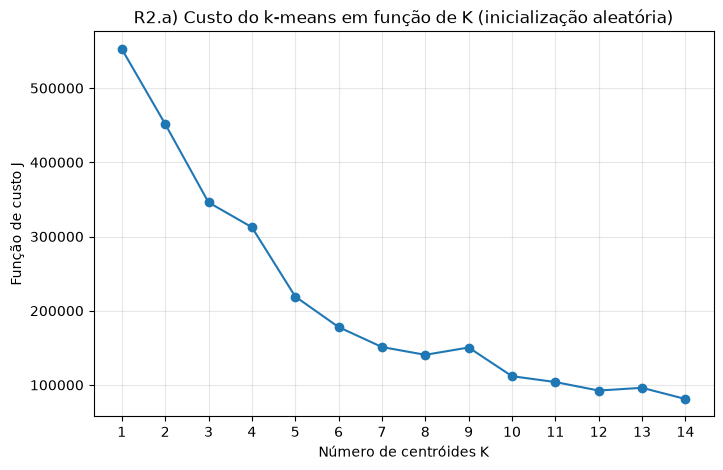

K =  1 ->  2: J desce 101004.45  ( 18.3%)
K =  2 ->  3: J desce 105676.93  ( 23.4%)
K =  3 ->  4: J desce  33425.94  (  9.7%)
K =  4 ->  5: J desce  93387.68  ( 29.9%)
K =  5 ->  6: J desce  41175.15  ( 18.8%)
K =  6 ->  7: J desce  26903.53  ( 15.1%)
K =  7 ->  8: J desce  10512.18  (  7.0%)
K =  8 ->  9: J desce  -9874.45  ( -7.0%)
K =  9 -> 10: J desce  38668.33  ( 25.7%)
K = 10 -> 11: J desce   7870.01  (  7.0%)
K = 11 -> 12: J desce  11467.87  ( 11.0%)
K = 12 -> 13: J desce  -3695.34  ( -4.0%)
K = 13 -> 14: J desce  15070.92  ( 15.7%)


In [ ]:

# R2A 


import matplotlib.pyplot as plt

testar_k = range(1, 15)          # testar K de 1 a 15
custos_random = []

for K in testar_k:
    centroides, atribuir = kmeans(X_norm, K, 'random')
    _, J = kmeans_custo(X_norm, centroides, atribuir)
    custos_random.append(J)
    print(f"K = {K:2d}  ->  J = {J:.2f}")

plt.figure(figsize=(8, 5))
plt.plot(testar_k, custos_random, 'o-')
plt.xlabel('Número de centróides K')
plt.ylabel('Função de custo J')
plt.title('R2.a) Custo do k-means em função de K (inicialização aleatória)')
plt.xticks(list(testar_k))
plt.grid(True, alpha=0.3)
plt.savefig('PartI_R2a.jpg', dpi=150, bbox_inches='tight')
plt.show()

# quanto o custo desce de K-1 para K (ajuda a encontrar o cotovelo)
ganhos = -np.diff(custos_random)
ganho_relativo = ganhos / np.array(custos_random[:-1]) * 100
for K, g, r in zip(list(testar_k)[1:], ganhos, ganho_relativo):
    print(f"K = {K-1:2d} -> {K:2d}: J desce {g:9.2f}  ({r:5.1f}%)")

K =  1  ->  J = 552684.00
K =  2  ->  J = 401477.00
K =  3  ->  J = 291317.89
K =  4  ->  J = 247808.31
K =  5  ->  J = 205756.40
K =  6  ->  J = 170150.58
K =  7  ->  J = 143062.32
K =  8  ->  J = 129793.62
K =  9  ->  J = 120380.97
K = 10  ->  J = 117648.38
K = 11  ->  J = 96171.89
K = 12  ->  J = 96768.65
K = 13  ->  J = 88546.39
K = 14  ->  J = 82274.55


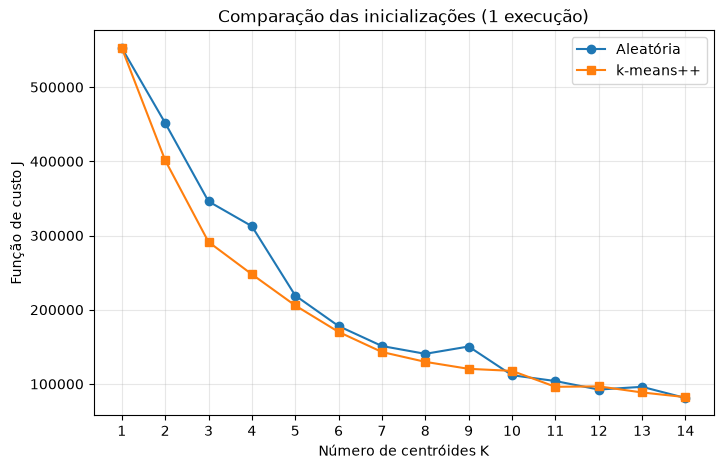

K =  1 ->  2: J desce 151207.00  ( 27.4%)
K =  2 ->  3: J desce 110159.11  ( 27.4%)
K =  3 ->  4: J desce  43509.58  ( 14.9%)
K =  4 ->  5: J desce  42051.91  ( 17.0%)
K =  5 ->  6: J desce  35605.82  ( 17.3%)
K =  6 ->  7: J desce  27088.26  ( 15.9%)
K =  7 ->  8: J desce  13268.70  (  9.3%)
K =  8 ->  9: J desce   9412.65  (  7.3%)
K =  9 -> 10: J desce   2732.59  (  2.3%)
K = 10 -> 11: J desce  21476.49  ( 18.3%)
K = 11 -> 12: J desce   -596.77  ( -0.6%)
K = 12 -> 13: J desce   8222.27  (  8.5%)
K = 13 -> 14: J desce   6271.84  (  7.1%)


In [ ]:

#R2B



#custo x K, inicialização k-means++ 
custos_kmpp = []

for K in testar_k:
    centroides, atribuir = kmeans(X_norm, K, 'km++')
    _, J = kmeans_custo(X_norm, centroides, atribuir)
    custos_kmpp.append(J)
    print(f"K = {K:2d}  ->  J = {J:.2f}")

plt.figure(figsize=(8, 5))
plt.plot(testar_k, custos_random, 'o-', label='Aleatória')
plt.plot(testar_k, custos_kmpp, 's-', label='k-means++')
plt.xlabel('Número de centróides K')
plt.ylabel('Função de custo J')
plt.title('Comparação das inicializações (1 execução)')
plt.xticks(list(testar_k))
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

# quanto o custo desce de K-1 para K
ganhos = -np.diff(custos_kmpp)
ganho_relativo = ganhos / np.array(custos_kmpp[:-1]) * 100
for K, g, r in zip(list(testar_k)[1:], ganhos, ganho_relativo):
    print(f"K = {K-1:2d} -> {K:2d}: J desce {g:9.2f}  ({r:5.1f}%)")

execução 1/20 concluída
execução 2/20 concluída
execução 3/20 concluída
execução 4/20 concluída
execução 5/20 concluída
execução 6/20 concluída
execução 7/20 concluída
execução 8/20 concluída
execução 9/20 concluída
execução 10/20 concluída
execução 11/20 concluída
execução 12/20 concluída
execução 13/20 concluída
execução 14/20 concluída
execução 15/20 concluída
execução 16/20 concluída
execução 17/20 concluída
execução 18/20 concluída
execução 19/20 concluída
execução 20/20 concluída


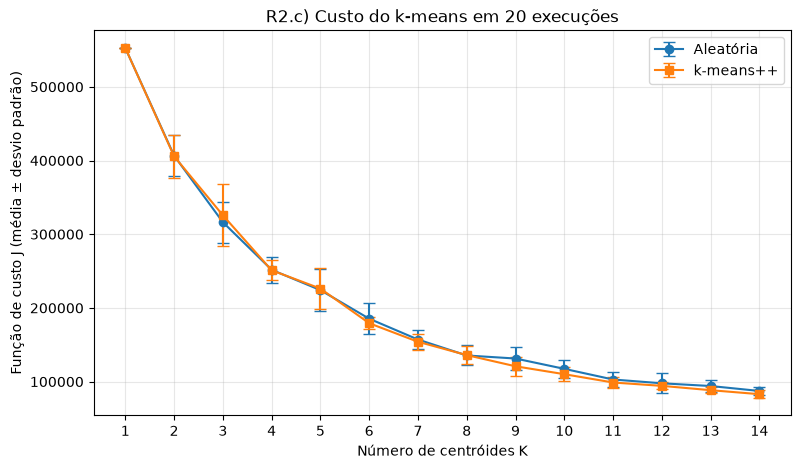

 K |  média aleat. |  dp aleat. |  média km++ |   dp km++
 1 |      552684.0 |        0.0 |    552684.0 |       0.0
 2 |      406653.7 |    27736.3 |    405743.0 |   29151.3
 3 |      316341.5 |    27755.3 |    325704.0 |   42043.2
 4 |      251708.6 |    17740.5 |    251057.9 |   13771.7
 5 |      224151.0 |    28056.4 |    226230.9 |   27885.4
 6 |      185368.3 |    21391.9 |    179233.8 |    8110.3
 7 |      157105.3 |    12659.5 |    154078.1 |   10849.7
 8 |      135479.9 |    13558.2 |    135981.0 |   12170.2
 9 |      131341.6 |    15515.7 |    120813.2 |   13121.4
10 |      117334.4 |    12551.0 |    110081.0 |    9372.3
11 |      102876.4 |     9625.9 |     98798.5 |    7197.7
12 |       97728.3 |    13433.4 |     94256.7 |    4715.7
13 |       94036.2 |     8718.8 |     88379.7 |    3810.2
14 |       87327.6 |     5569.9 |     82968.2 |    5182.7


In [ ]:
#R2C




#20 execsde cada inicialização 
n_runs = 20
testar_k_lista = list(testar_k)

J_random = np.zeros((n_runs, len(testar_k_lista)))   # linhas = execuções, colunas = K
J_kmpp   = np.zeros((n_runs, len(testar_k_lista)))

for r in range(n_runs):
    for i, K in enumerate(testar_k_lista):
        centroides, atribuir = kmeans(X_norm, K, 'random')
        _, J_random[r, i] = kmeans_custo(X_norm, centroides, atribuir)

        centroides, atribuir = kmeans(X_norm, K, 'km++')
        _, J_kmpp[r, i] = kmeans_custo(X_norm, centroides, atribuir)
    print(f"execução {r+1}/{n_runs} concluída")

# média e desvio padrão para cada K (ao longo das 20 execuções)
media_rand, dp_rand = J_random.mean(axis=0), J_random.std(axis=0)
media_kpp,  dp_kpp  = J_kmpp.mean(axis=0),   J_kmpp.std(axis=0)

plt.figure(figsize=(9, 5))
plt.errorbar(testar_k_lista, media_rand, yerr=dp_rand, fmt='o-', capsize=4, label='Aleatória')
plt.errorbar(testar_k_lista, media_kpp,  yerr=dp_kpp,  fmt='s-', capsize=4, label='k-means++')
plt.xlabel('Número de centróides K')
plt.ylabel('Função de custo J (média ± desvio padrão)')
plt.title('R2.c) Custo do k-means em 20 execuções')
plt.xticks(testar_k_lista)
plt.legend()
plt.grid(True, alpha=0.3)
plt.savefig('PartI_R2c.jpg', dpi=150, bbox_inches='tight')
plt.show()

print(" K |  média aleat. |  dp aleat. |  média km++ |   dp km++")
for i, K in enumerate(testar_k_lista):
    print(f"{K:2d} | {media_rand[i]:13.1f} | {dp_rand[i]:10.1f} | {media_kpp[i]:11.1f} | {dp_kpp[i]:9.1f}")

In [ ]:
#Auxiliar R2C


diferenca_media = (media_kpp - media_rand) / media_rand * 100   # negativo = km++ melhor
print(" K | dif. média (%) | dp aleat. | dp km++ | menor dp")
for i, K in enumerate(testar_k_lista):
    menor = 'km++' if dp_kpp[i] < dp_rand[i] else 'aleat.'
    print(f"{K:2d} | {diferenca_media[i]:+13.1f}  | {dp_rand[i]:9.0f} | {dp_kpp[i]:7.0f} | {menor}")

print("\nK em que km++ tem média menor:", [K for K, d in zip(testar_k_lista, diferenca_media) if d < 0])
print("K em que km++ tem dp menor:    ", [K for K, a, b in zip(testar_k_lista, dp_rand, dp_kpp) if b < a])

 K | dif. média (%) | dp aleat. | dp km++ | menor dp
 1 |          +0.0  |         0 |       0 | aleat.
 2 |          -0.2  |     27736 |   29151 | aleat.
 3 |          +3.0  |     27755 |   42043 | aleat.
 4 |          -0.3  |     17741 |   13772 | km++
 5 |          +0.9  |     28056 |   27885 | km++
 6 |          -3.3  |     21392 |    8110 | km++
 7 |          -1.9  |     12660 |   10850 | km++
 8 |          +0.4  |     13558 |   12170 | km++
 9 |          -8.0  |     15516 |   13121 | km++
10 |          -6.2  |     12551 |    9372 | km++
11 |          -4.0  |      9626 |    7198 | km++
12 |          -3.6  |     13433 |    4716 | km++
13 |          -6.0  |      8719 |    3810 | km++
14 |          -5.0  |      5570 |    5183 | km++

K em que km++ tem média menor: [2, 4, 6, 7, 9, 10, 11, 12, 13, 14]
K em que km++ tem dp menor:     [4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14]


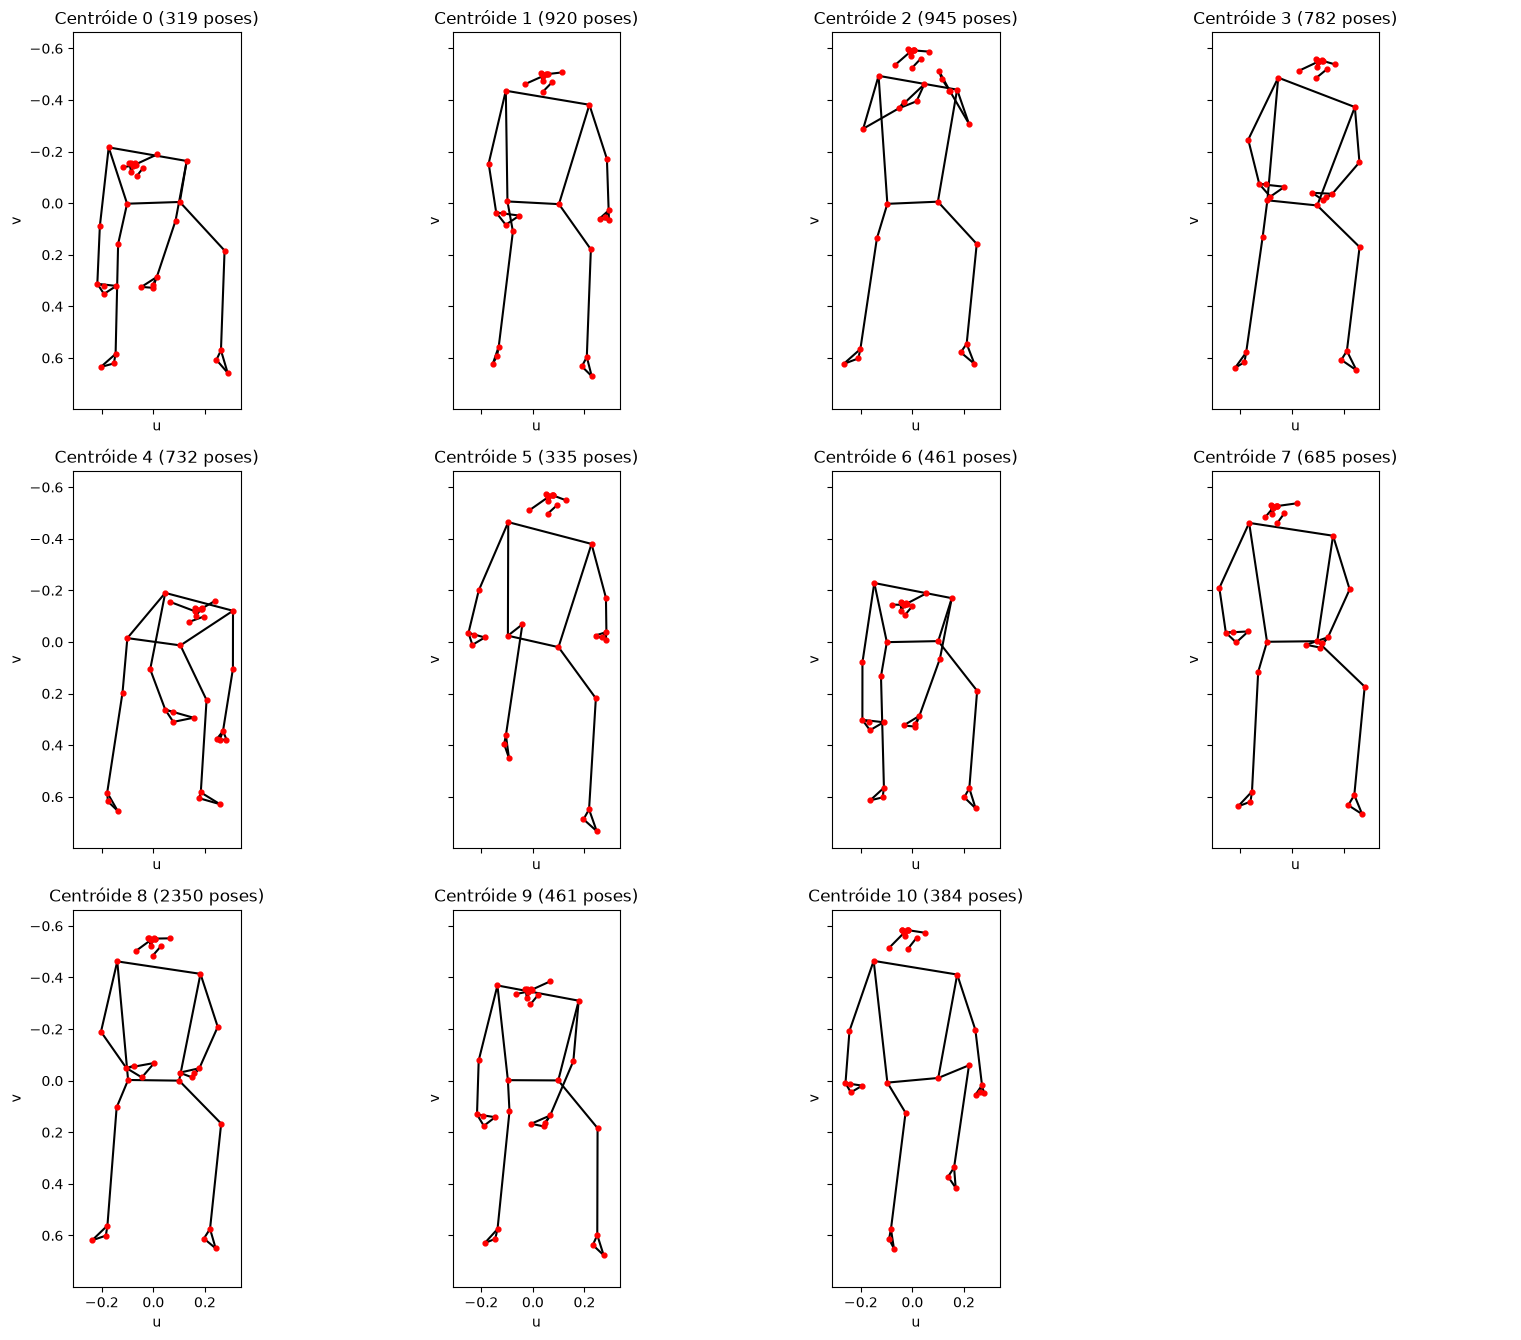

In [ ]:
#R3A


# visualização das poses dos centróides 
LIGACOES = [
    # cara
    (0, 1), (1, 2), (2, 3), (3, 7), (0, 4), (4, 5), (5, 6), (6, 8), (9, 10),
    # tronco
    (11, 12), (11, 23), (12, 24), (23, 24),
    # braço (11) e mão
    (11, 13), (13, 15), (15, 17), (15, 19), (15, 21), (17, 19),
    # braço (12) e mão
    (12, 14), (14, 16), (16, 18), (16, 20), (16, 22), (18, 20),
    # perna (23) e pé
    (23, 25), (25, 27), (27, 29), (29, 31), (27, 31),
    # perna (24) e pé
    (24, 26), (26, 28), (28, 30), (30, 32), (28, 32),
]

def desenhar_pose(pose, ax, titulo=None):
    # pose = [u0, v0, u1, v1, ..., u32, v32]
    u = pose[0::2]     #par -> coordenadas u
    v = pose[1::2]     #ímpar -> coordenadas v
    for a, b in LIGACOES:
        ax.plot([u[a], u[b]], [v[a], v[b]], 'k-', lw=1.5)
    ax.scatter(u, v, c='red', s=12, zorder=3)
    ax.set_aspect('equal')
    ax.invert_yaxis()            # em imagem, v cresce para baixo
    ax.set_xlabel('u')
    ax.set_ylabel('v')
    if titulo:
        ax.set_title(titulo)


# centróides do modelo escolhido 
K_escolhido = 11
init_escolhida = 'km++'

centroides, atribuir = kmeans(X_norm, K_escolhido, init_escolhida)
centroides_reais = scaler.inverse_transform(centroides)   # desfazer a normalização
tamanhos = np.bincount(atribuir, minlength=K_escolhido)

n_cols = 4
n_rows = int(np.ceil(K_escolhido / n_cols))
fig, axes = plt.subplots(n_rows, n_cols, figsize=(4 * n_cols, 4.5 * n_rows), sharex=True, sharey=True)
axes = axes.ravel()

for k in range(K_escolhido):
    desenhar_pose(centroides_reais[k], axes[k], f'Centróide {k} ({tamanhos[k]} poses)')
for ax in axes[K_escolhido:]:
    ax.axis('off')       # esconder os quadrados vazios

plt.tight_layout()
plt.savefig('PartI_R3a.jpg', dpi=150, bbox_inches='tight')
plt.show()

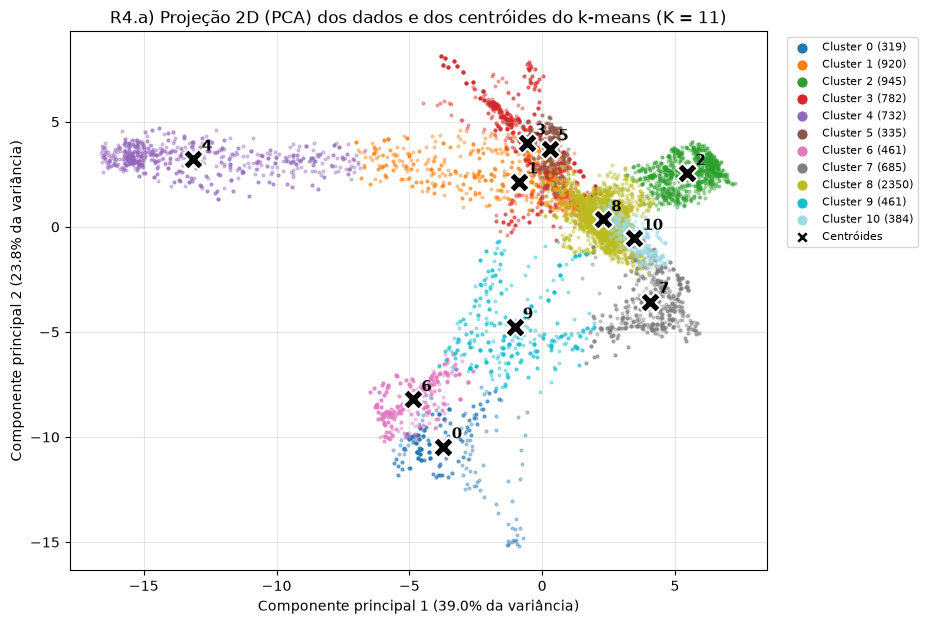

In [ ]:
#R4A


# utlizando funções do PCA da R6, do pca.py
def pca_fit(X):
    media = X.mean(axis=0)
    Xc = X - media
    cov = (Xc.T @ Xc) / (X.shape[0] - 1)        # matriz de covariância (d, d)
    valores, vetores = np.linalg.eigh(cov)
    ordem = np.argsort(valores)[::-1]            # da maior variância para a menor
    return media, valores[ordem], vetores[:, ordem]

def pca_project(X, media, W, r):
    return (X - media) @ W[:, :r]


# ===== R4.a: projeção 2D dos dados e dos centróides =====
assert centroides.shape == (11, 66), "centroides não é o modelo da R3a"

media, valores, W = pca_fit(X_norm)
var_ratio = valores / valores.sum()

Z2 = pca_project(X_norm, media, W, r=2)          # poses em 2D, (8374, 2)
C2 = pca_project(centroides, media, W, r=2)      # centróides em 2D, (11, 2)

cores = plt.cm.tab20(np.linspace(0, 1, K_escolhido))

plt.figure(figsize=(9, 7))
for k in range(K_escolhido):
    pts = Z2[atribuir == k]
    plt.scatter(pts[:, 0], pts[:, 1], s=4, alpha=0.35, color=cores[k],
                label=f'Cluster {k} ({len(pts)})')

# centróides: marcador diferente, com o número ao lado
plt.scatter(C2[:, 0], C2[:, 1], marker='X', s=220, c='black',
            edgecolors='white', linewidths=1.5, zorder=3, label='Centróides')
for k, (x, y) in enumerate(C2):
    plt.annotate(str(k), (x, y), xytext=(6, 6), textcoords='offset points',
                 fontsize=11, fontweight='bold')

plt.xlabel(f'Componente principal 1 ({var_ratio[0]:.1%} da variância)')
plt.ylabel(f'Componente principal 2 ({var_ratio[1]:.1%} da variância)')
plt.title('R4.a) Projeção 2D (PCA) dos dados e dos centróides do k-means (K = 11)')
leg = plt.legend(fontsize=8, bbox_to_anchor=(1.02, 1), loc='upper left')
for h in leg.legend_handles[:-1]:      # clusters: pontos maiores e opacos
    h.set_sizes([40])
    h.set_alpha(1)
leg.legend_handles[-1].set_sizes([90]) # centróides: X de tamanho normal
plt.grid(True, alpha=0.3)
plt.savefig('PartI4a.jpg', dpi=150, bbox_inches='tight')
plt.show()

r = 8 | variância explicada = 95.25% | Z: (8374, 8)
K =  1 | BIC =   293396.2 | AIC =   293086.8
K =  2 | BIC =   241377.6 | AIC =   240751.6
K =  3 | BIC =   232017.5 | AIC =   231075.1
K =  4 | BIC =   203024.7 | AIC =   201765.8
K =  5 | BIC =   189588.0 | AIC =   188012.6
K =  6 | BIC =   185172.5 | AIC =   183280.7
K =  7 | BIC =   179833.5 | AIC =   177625.1
K =  8 | BIC =   174020.7 | AIC =   171495.9
K =  9 | BIC =   168868.8 | AIC =   166027.6
K = 10 | BIC =   165586.2 | AIC =   162428.4
K = 11 | BIC =   163314.0 | AIC =   159839.7
K = 12 | BIC =   160912.6 | AIC =   157121.9
K = 13 | BIC =   160917.2 | AIC =   156810.0
K = 14 | BIC =   158191.9 | AIC =   153768.2
K = 15 | BIC =   156483.6 | AIC =   151743.5
K = 16 | BIC =   154556.3 | AIC =   149499.6
K = 17 | BIC =   154081.7 | AIC =   148708.6
K = 18 | BIC =   150203.3 | AIC =   144513.7
K = 19 | BIC =   149924.6 | AIC =   143918.5
K = 20 | BIC =   151063.2 | AIC =   144740.6
K = 21 | BIC =   147741.9 | AIC =   141102.9
K =

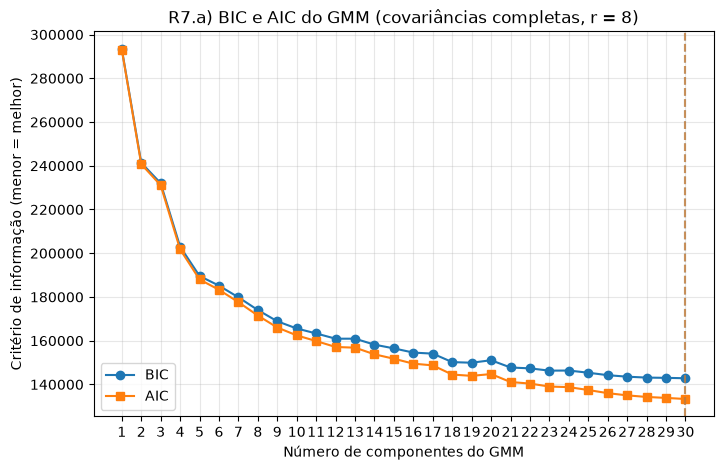

In [ ]:
#R7A



from sklearn.mixture import GaussianMixture

var_acum = np.cumsum(var_ratio)
r_95 = int(np.argmax(var_acum >= 0.95)) + 1
Z = pca_project(X_norm, media, W, r=r_95)
print(f"r = {r_95} | variância explicada = {var_acum[r_95-1]:.2%} | Z: {Z.shape}")


# ===== R7.a: escolha do número de componentes do GMM =====
Ks_gmm = list(range(1, 31))
bic, aic = [], []

for k in Ks_gmm:
    gmm = GaussianMixture(n_components=k, covariance_type='full',
                          n_init=5, random_state=555)
    gmm.fit(Z)
    bic.append(gmm.bic(Z))
    aic.append(gmm.aic(Z))
    print(f"K = {k:2d} | BIC = {bic[-1]:10.1f} | AIC = {aic[-1]:10.1f}")

k_bic = Ks_gmm[int(np.argmin(bic))]
k_aic = Ks_gmm[int(np.argmin(aic))]
print(f"\nMínimo do BIC: K = {k_bic} | Mínimo do AIC: K = {k_aic}")

plt.figure(figsize=(8, 5))
plt.plot(Ks_gmm, bic, 'o-', label='BIC')
plt.plot(Ks_gmm, aic, 's-', label='AIC')
plt.axvline(k_bic, color='tab:blue', linestyle='--', alpha=0.6)
plt.axvline(k_aic, color='tab:orange', linestyle='--', alpha=0.6)
plt.xlabel('Número de componentes do GMM')
plt.ylabel('Critério de informação (menor = melhor)')
plt.title(f'R7.a) BIC e AIC do GMM (covariâncias completas, r = {r_95})')
plt.xticks(Ks_gmm)
plt.legend()
plt.grid(True, alpha=0.3)
plt.savefig('PartIII7a.jpg', dpi=150, bbox_inches='tight')
plt.show()

In [ ]:
#Auxiliar R7A


desc_bic = -np.diff(bic) / np.array(bic[:-1]) * 100
for k, d in zip(Ks_gmm[1:], desc_bic):
    print(f"K = {k-1:2d} -> {k:2d}: BIC desce {d:5.1f}%")

K =  1 ->  2: BIC desce  17.7%
K =  2 ->  3: BIC desce   3.9%
K =  3 ->  4: BIC desce  12.5%
K =  4 ->  5: BIC desce   6.6%
K =  5 ->  6: BIC desce   2.3%
K =  6 ->  7: BIC desce   2.9%
K =  7 ->  8: BIC desce   3.2%
K =  8 ->  9: BIC desce   3.0%
K =  9 -> 10: BIC desce   1.9%
K = 10 -> 11: BIC desce   1.4%
K = 11 -> 12: BIC desce   1.5%
K = 12 -> 13: BIC desce  -0.0%
K = 13 -> 14: BIC desce   1.7%
K = 14 -> 15: BIC desce   1.1%
K = 15 -> 16: BIC desce   1.2%
K = 16 -> 17: BIC desce   0.3%
K = 17 -> 18: BIC desce   2.5%
K = 18 -> 19: BIC desce   0.2%
K = 19 -> 20: BIC desce  -0.8%
K = 20 -> 21: BIC desce   2.2%
K = 21 -> 22: BIC desce   0.3%
K = 22 -> 23: BIC desce   0.7%
K = 23 -> 24: BIC desce  -0.0%
K = 24 -> 25: BIC desce   0.7%
K = 25 -> 26: BIC desce   0.8%
K = 26 -> 27: BIC desce   0.5%
K = 27 -> 28: BIC desce   0.3%
K = 28 -> 29: BIC desce   0.1%
K = 29 -> 30: BIC desce   0.1%


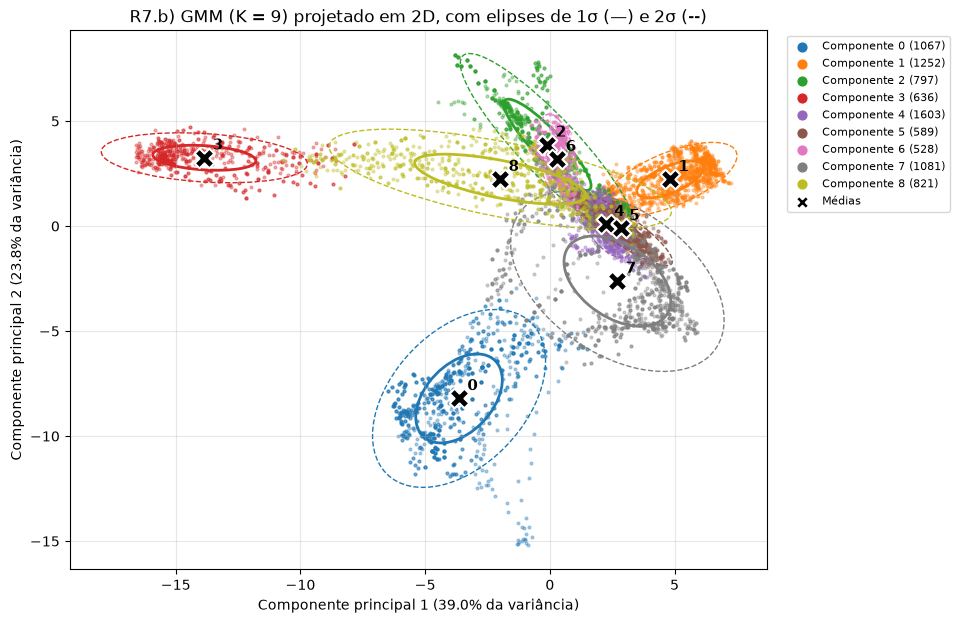

 k | peso  | n poses | confiança média
 0 | 0.127 |    1067 | 0.992
 1 | 0.150 |    1252 | 0.990
 2 | 0.096 |     797 | 0.961
 3 | 0.076 |     636 | 0.991
 4 | 0.190 |    1603 | 0.977
 5 | 0.069 |     589 | 0.983
 6 | 0.064 |     528 | 0.989
 7 | 0.129 |    1081 | 0.974
 8 | 0.098 |     821 | 0.986


In [ ]:
# R7B: GMM final e visualização com covariâncias 
from matplotlib.patches import Ellipse

K_gmm = 9   # <- escolhido na R7a
gmm = GaussianMixture(n_components=K_gmm, covariance_type='full',
                      n_init=5, random_state=555).fit(Z)
labels_gmm = gmm.predict(Z)                    # componente mais provável de cada pose
prob_max = gmm.predict_proba(Z).max(axis=1)    # confiança dessa atribuição

# as 2 primeiras colunas de Z são a mesma projeção 2D da R4a
assert np.allclose(Z[:, :2], Z2)

def desenhar_elipse(media2, cov2, ax, cor, n_std):
    """Elipse de n_std desvios padrão de uma gaussiana 2D."""
    vals, vecs = np.linalg.eigh(cov2)              # eixos principais da elipse
    ordem = vals.argsort()[::-1]
    vals, vecs = vals[ordem], vecs[:, ordem]
    angulo = np.degrees(np.arctan2(vecs[1, 0], vecs[0, 0]))
    largura, altura = 2 * n_std * np.sqrt(vals)
    ax.add_patch(Ellipse(media2, largura, altura, angle=angulo, fill=False,
                         edgecolor=cor, lw=2 if n_std == 1 else 1,
                         linestyle='-' if n_std == 1 else '--'))

cores_gmm = plt.cm.tab10(np.arange(K_gmm))
fig, ax = plt.subplots(figsize=(9, 7))

for k in range(K_gmm):
    pts = Z[labels_gmm == k, :2]
    ax.scatter(pts[:, 0], pts[:, 1], s=4, alpha=0.35, color=cores_gmm[k],
               label=f'Componente {k} ({len(pts)})')
    media2 = gmm.means_[k, :2]                     # média nas 2 primeiras PCs
    cov2 = gmm.covariances_[k][:2, :2]             # bloco 2x2 da covariância
    desenhar_elipse(media2, cov2, ax, cores_gmm[k], n_std=1)
    desenhar_elipse(media2, cov2, ax, cores_gmm[k], n_std=2)

ax.scatter(gmm.means_[:, 0], gmm.means_[:, 1], marker='X', s=200, c='black',
           edgecolors='white', linewidths=1.5, zorder=3, label='Médias')
for k, (x, y) in enumerate(gmm.means_[:, :2]):
    ax.annotate(str(k), (x, y), xytext=(6, 6), textcoords='offset points',
                fontsize=11, fontweight='bold')

ax.set_xlabel(f'Componente principal 1 ({var_ratio[0]:.1%} da variância)')
ax.set_ylabel(f'Componente principal 2 ({var_ratio[1]:.1%} da variância)')
ax.set_title(f'R7.b) GMM (K = {K_gmm}) projetado em 2D, com elipses de 1σ (—) e 2σ (--)')
leg = ax.legend(fontsize=8, bbox_to_anchor=(1.02, 1), loc='upper left')
for h in leg.legend_handles[:-1]:
    h.set_sizes([40]); h.set_alpha(1)
leg.legend_handles[-1].set_sizes([90])
ax.grid(True, alpha=0.3)
plt.savefig('PartIII7b.jpg', dpi=150, bbox_inches='tight')
plt.show()

# tabela de apoio
print(" k | peso  | n poses | confiança média")
for k in range(K_gmm):
    m = labels_gmm == k
    print(f"{k:2d} | {gmm.weights_[k]:.3f} | {m.sum():7d} | {prob_max[m].mean():.3f}")

In [ ]:
#Auxiliar R7B

# quantas poses de cada cluster do k-means (linhas) caem em cada componente do GMM (colunas)
tab = pd.crosstab(pd.Series(atribuir, name='k-means'), pd.Series(labels_gmm, name='GMM'))
print(tab)

GMM        0    1    2    3     4    5    6    7    8
k-means                                              
0        319    0    0    0     0    0    0    0    0
1          0    0    2    0     0  205  193    0  520
2          0  945    0    0     0    0    0    0    0
3          0    0  642    0     0    0    0  140    0
4          0    0    0  636     0    0    0    0   96
5          0    0    0    0     0    0  335    0    0
6        461    0    0    0     0    0    0    0    0
7          0    0    1    0     4    0    0  680    0
8          0  307  152    0  1599    0    0   87  205
9        287    0    0    0     0    0    0  174    0
10         0    0    0    0     0  384    0    0    0


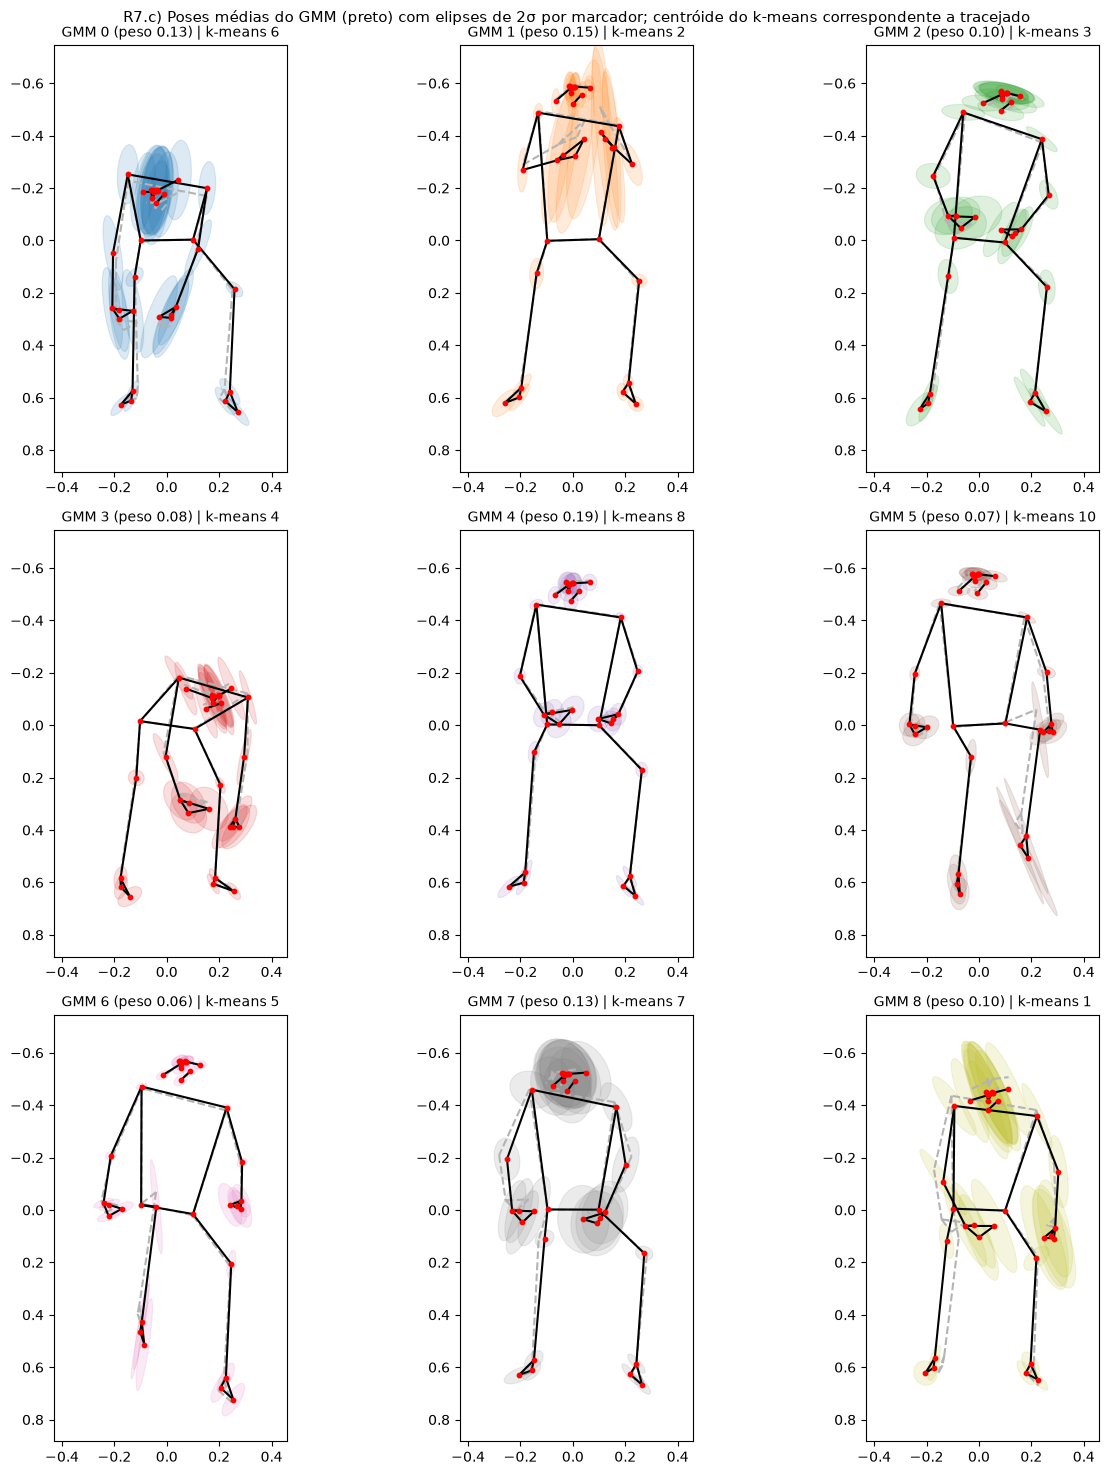

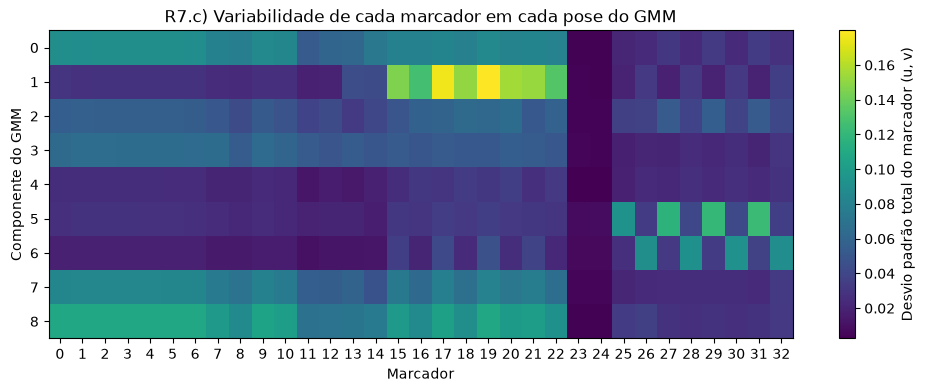

In [ ]:
# R7c: poses do GMM no espaço original






def gmm_para_espaco_original(gmm, W, media, scaler):
    #Converte médias e covariâncias do GMM (espaço PCA, r dims) para o espaço
    #original dos esqueletos (66 dims, coordenadas u, v).
    r = gmm.means_.shape[1]
    Wr = W[:, :r]                                   # (66, r)
    D = np.diag(scaler.scale_)                      # desvios padrão do StandardScaler
    poses, covs = [], []
    for k in range(gmm.n_components):
        mu_norm = Wr @ gmm.means_[k] + media                    # (66,)
        cov_norm = Wr @ gmm.covariances_[k] @ Wr.T              # (66, 66)
        poses.append(scaler.inverse_transform(mu_norm[None, :])[0])
        covs.append(D @ cov_norm @ D)
    return np.array(poses), np.array(covs)


def desenhar_pose_cov(pose, cov, ax, cor='tab:blue', n_std=2, titulo=None, pose_ref=None):
    #Desenha uma pose com a elipse de covariância (n_std) de cada marcador.
    #pose_ref: pose do k-means a sobrepor (cinzento), para comparação.
    if pose_ref is not None:
        u_r, v_r = pose_ref[0::2], pose_ref[1::2]
        for a, b in LIGACOES:
            ax.plot([u_r[a], u_r[b]], [v_r[a], v_r[b]], color='0.7', lw=1.5, ls='--')
    u, v = pose[0::2], pose[1::2]
    for j in range(33):
        c2 = cov[2*j:2*j+2, 2*j:2*j+2]              # bloco 2x2 (u_j, v_j)
        vals, vecs = np.linalg.eigh(c2)
        ang = np.degrees(np.arctan2(vecs[1, 1], vecs[0, 1]))   # eixo maior
        ax.add_patch(Ellipse((u[j], v[j]),
                             2 * n_std * np.sqrt(max(vals[1], 0)),
                             2 * n_std * np.sqrt(max(vals[0], 0)),
                             angle=ang, facecolor=cor, alpha=0.15, edgecolor=cor, lw=0.8))
    for a, b in LIGACOES:
        ax.plot([u[a], u[b]], [v[a], v[b]], 'k-', lw=1.5)
    ax.scatter(u, v, c='red', s=10, zorder=3)
    ax.set_aspect('equal')
    if titulo:
        ax.set_title(titulo, fontsize=10)


poses_gmm, covs_gmm = gmm_para_espaco_original(gmm, W, media, scaler)

# cluster do k-means com mais poses em cada componente do GMM (da tabela cruzada)
mapa_km = tab.idxmax(axis=0)

fig, axes = plt.subplots(3, 3, figsize=(13, 15))
for k, ax in enumerate(axes.ravel()):
    km = int(mapa_km[k])
    desenhar_pose_cov(poses_gmm[k], covs_gmm[k], ax, cor=cores_gmm[k],
                      titulo=f'GMM {k} (peso {gmm.weights_[k]:.2f}) | k-means {km}',
                      pose_ref=centroides_reais[km])

# mesma escala em todos os subgráficos e v  cresce p baixo
todas = np.vstack([poses_gmm, centroides_reais])
umin, umax = todas[:, 0::2].min(), todas[:, 0::2].max()
vmin, vmax = todas[:, 1::2].min(), todas[:, 1::2].max()
for ax in axes.ravel():
    ax.set_xlim(umin - 0.15, umax + 0.15)
    ax.set_ylim(vmax + 0.15, vmin - 0.15)        # invertido: cabeça em cima
plt.suptitle('R7.c) Poses médias do GMM (preto) com elipses de 2σ por marcador; '
             'centróide do k-means correspondente a tracejado', fontsize=11)
plt.tight_layout()
plt.savefig('PartIII7c.jpg', dpi=150, bbox_inches='tight')
plt.show()


# Variância por marcador e pose
dp_marcador = np.array([[np.sqrt(np.trace(covs_gmm[k][2*j:2*j+2, 2*j:2*j+2]))
                         for j in range(33)] for k in range(K_gmm)])   # (K, 33)

plt.figure(figsize=(12, 4))
plt.imshow(dp_marcador, aspect='auto', cmap='viridis')
plt.colorbar(label='Desvio padrão total do marcador (u, v)')
plt.xlabel('Marcador'); plt.ylabel('Componente do GMM')
plt.xticks(range(33)); plt.yticks(range(K_gmm))
plt.title('R7.c) Variabilidade de cada marcador em cada pose do GMM')
plt.savefig('PartIII7c_var.jpg', dpi=150, bbox_inches='tight')
plt.show()

movimento | silhueta: 2:0.63 3:0.77 4:0.76 5:0.64 6:0.63 7:0.63 8:0.50 9:0.42 10:0.42
poses | silhueta: 2:0.48 3:0.66 4:0.63 5:0.61 6:0.62 7:0.58 8:0.51 9:0.53 10:0.53


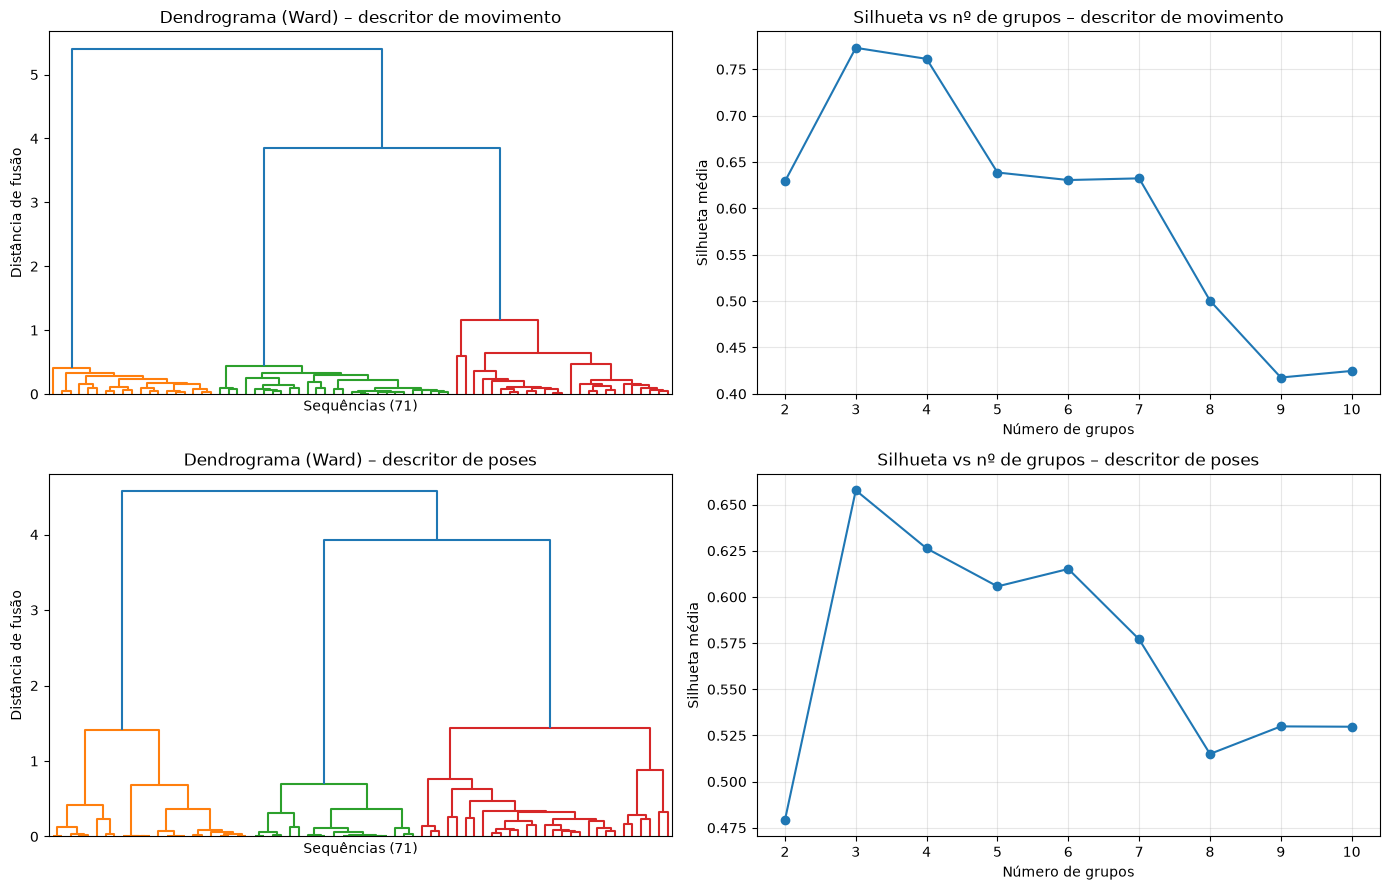

In [ ]:
# Q9





from scipy.cluster.hierarchy import linkage, fcluster, dendrogram
from sklearn.metrics import silhouette_score

seqs = df_train['Skeleton_Sequence'].to_numpy()
n_seq = len(seqs)
tam = np.array([s.shape[0] for s in seqs])            # nº de frames de cada sequência
lim = np.concatenate([[0], np.cumsum(tam)])           # onde começa cada sequência em X
assert lim[-1] == X.shape[0]

# Descritor 1: assinatura de movimento (quanto varia cada coordenada na sequência)
F_mov = np.array([s.std(axis=0) for s in seqs])                       # (71, 66)
F_mov = F_mov / np.linalg.norm(F_mov, axis=1, keepdims=True)          # padrão, não amplitude

# Descritor 2: saco de poses (fração de frames em cada componente do GMM)
F_pose = np.array([np.bincount(labels_gmm[lim[i]:lim[i+1]], minlength=K_gmm) / tam[i]
                   for i in range(n_seq)])                            # (71, K_gmm)

descritores = {'movimento': F_mov, 'poses': F_pose}
ks = list(range(2, 11))
ligacoes = {}

fig, axes = plt.subplots(2, 2, figsize=(14, 9))
for lin, (nome, F) in enumerate(descritores.items()):
    Lk = linkage(F, method='ward')
    ligacoes[nome] = Lk
    dendrogram(Lk, ax=axes[lin, 0], no_labels=True)
    axes[lin, 0].set_title(f'Dendrograma (Ward) – descritor de {nome}')
    axes[lin, 0].set_xlabel('Sequências (71)')
    axes[lin, 0].set_ylabel('Distância de fusão')

    sil = [silhouette_score(F, fcluster(Lk, k, 'maxclust')) for k in ks]
    axes[lin, 1].plot(ks, sil, 'o-')
    axes[lin, 1].set_title(f'Silhueta vs nº de grupos – descritor de {nome}')
    axes[lin, 1].set_xlabel('Número de grupos')
    axes[lin, 1].set_ylabel('Silhueta média')
    axes[lin, 1].set_xticks(ks)
    axes[lin, 1].grid(True, alpha=0.3)
    print(nome, '| silhueta:', ' '.join(f'{k}:{s:.2f}' for k, s in zip(ks, sil)))

plt.tight_layout()
plt.savefig('PartIV9a.jpg', dpi=150, bbox_inches='tight')
plt.show()

Concordância entre os dois descritores:
poses       0   1   2
movimento            
0           0  19   0
1           0   0  27
2          23   0   2

Exercício 0: 19 sequências | duração média 59 frames
  marcadores que mais se mexem: pé E, calcanhar E, tornozelo E, joelho E, calcanhar D
  componentes GMM mais frequentes: GMM 5 (53%), GMM 6 (47%), GMM 8 (0%)

Exercício 1: 27 sequências | duração média 204 frames
  marcadores que mais se mexem: olho E, olho E ext, olho D int, olho D, nariz
  componentes GMM mais frequentes: GMM 4 (22%), GMM 7 (20%), GMM 0 (19%)

Exercício 2: 25 sequências | duração média 70 frames
  marcadores que mais se mexem: indicador E, mindinho E, polegar E, pulso E, mindinho D
  componentes GMM mais frequentes: GMM 1 (71%), GMM 4 (25%), GMM 2 (3%)


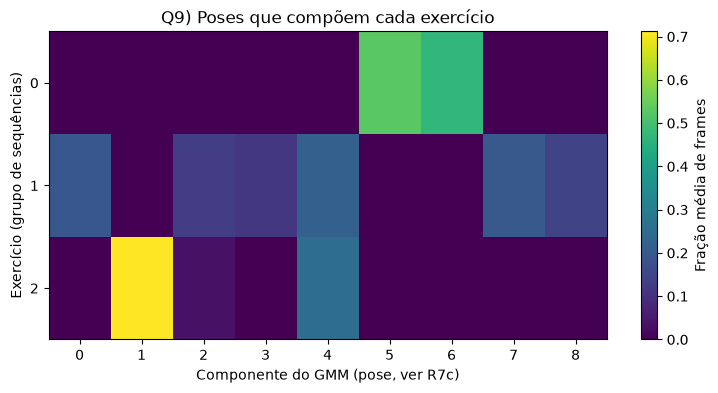

In [ ]:
# Q9: descrição de cada grupo
n_ex = 3 # o número que escolhemos foi o 3

grupos_mov  = fcluster(ligacoes['movimento'], n_ex, 'maxclust') - 1
grupos_pose = fcluster(ligacoes['poses'],     n_ex, 'maxclust') - 1
print("Concordância entre os dois descritores:")
print(pd.crosstab(pd.Series(grupos_mov, name='movimento'), pd.Series(grupos_pose, name='poses')))

nomes = ['nariz','olho E int','olho E','olho E ext','olho D int','olho D','olho D ext',
         'orelha E','orelha D','boca E','boca D','ombro E','ombro D','cotovelo E',
         'cotovelo D','pulso E','pulso D','mindinho E','mindinho D','indicador E',
         'indicador D','polegar E','polegar D','anca E','anca D','joelho E','joelho D',
         'tornozelo E','tornozelo D','calcanhar E','calcanhar D','pé E','pé D']

prop_ex = np.zeros((n_ex, K_gmm))
for e in range(n_ex):
    m = grupos_mov == e
    energia = F_mov[m].mean(0) ** 2
    energia = energia[0::2] + energia[1::2]          # u + v, por marcador
    top_m = np.argsort(energia)[::-1][:5]
    prop_ex[e] = F_pose[m].mean(0)
    top_p = np.argsort(prop_ex[e])[::-1][:3]
    print(f"\nExercício {e}: {m.sum()} sequências | duração média {tam[m].mean():.0f} frames")
    print("  marcadores que mais se mexem:", ', '.join(nomes[j] for j in top_m))
    print("  componentes GMM mais frequentes:",
          ', '.join(f'GMM {c} ({prop_ex[e, c]:.0%})' for c in top_p))

plt.figure(figsize=(9, 4))
plt.imshow(prop_ex, aspect='auto', cmap='viridis')
plt.colorbar(label='Fração média de frames')
plt.xlabel('Componente do GMM (pose, ver R7c)')
plt.ylabel('Exercício (grupo de sequências)')
plt.xticks(range(K_gmm)); plt.yticks(range(n_ex))
plt.title('Q9) Poses que compõem cada exercício')
plt.savefig('PartIV9b.jpg', dpi=150, bbox_inches='tight')
plt.show()

In [ ]:
#Auxiliar Q9

print(np.round(F_pose[grupos_mov == 0][:, [5, 6]], 2))


[[0.52 0.48]
 [0.72 0.28]
 [0.59 0.41]
 [0.46 0.54]
 [0.28 0.72]
 [0.57 0.43]
 [0.56 0.44]
 [0.54 0.46]
 [0.48 0.52]
 [0.56 0.44]
 [0.57 0.43]
 [0.53 0.47]
 [0.36 0.64]
 [0.44 0.56]
 [0.56 0.44]
 [0.64 0.36]
 [0.44 0.56]
 [0.56 0.44]
 [0.66 0.34]]
